# 05 — The boundary tested: other resorts, other DEMs, and what open data cannot settle

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Notebook 06 measures the hand-drawn operating boundary. This one spends its
whole length trying to break that measurement, and answers three questions an
engineering or GIS team would put to an outside analyst:

1. **Does the boundary look sane next to places that already work?** It is
   compared with Shymbulak and Oi-Qaragai under one corridor rule, at matched
   elevations and matched gradients.
2. **Will the model survive a different input?** The whole chain — slope,
   aspect, horizon, sky view factor, insolation, sunshine duration — is re-run
   on two independent DEMs and the *products* are compared, not the elevations.
3. **What do you still need from the ground?** Clear-sky geometry and a
   satellite snow-detection frequency are not a snowpack model. The last
   section says exactly which quantities cannot be settled from orbit.

### What the operator publishes, and what it does not

From the 18 November 2026 board meeting of Kazakh Tourism Development, chaired
by the Prime Minister, together with the company's own general plan: **60 km of
runs, 16 lifts of which 11 cableways are POMA's, 60.9 % of the runs green and
blue (10.6 % green + 50.3 % blue), 70 % of runs with snowmaking, up to 10 000
skiers a day, 1 022 ha of territory with about 20 ha built on, launch in
December 2028**, a mountain-village concept by BIG and timber base- and
top-station structures by Blumer-Lehmann, with Ecosign also engaged.

Press reporting of the April 2026 statement instead gave **17 lifts** and "about
70 % green and blue". The general plan attaches its own 70 % to *snowmaking*, so
the press figure is most likely a conflation; both are carried in `config.py`
and every table below names the source it used. See `METHODS.md` §28.

What is **not** published: any boundary, any station coordinate, any lift
alignment, any run, any elevation, and any capacity in persons per hour. So
**no boundary in this project is the operator's own**, and no planned lift is
drawn anywhere in this release. What is measured here is the author's drawn
boundary, and it is named as such on every figure.

In [1]:
import os
os.environ["KZ_AREA"] = "superski"         # must be set before importing config

import json
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ski_terrain as ST
from config import (AOI_BBOX_WGS84, AREA_LABEL, AREA_NOTE, HORIZON_N_AZIMUTH,
                    INTERIM, OUT_PNG, OUT_TAB, OUT_TIF, OUTLOOK_YEAR,
                    PLATEAU_POINT, PROJECT_AREA_HA, PROJECT_BUILT_HA,
                    PROJECT_CABLEWAYS_POMA, PROJECT_GREEN_BLUE_SHARE,
                    PROJECT_LAUNCH, PROJECT_LIFTS, PROJECT_PISTE_KM,
                    PROJECT_SKIERS_PER_DAY, SKIABLE_SLOPE_MAX, SKIABLE_SLOPE_MIN,
                    STUDY_AREAS, SUN_HOUR_STEP_MIN)
from dem import write_geotiff
from grids import DEM_GRID, S2_GRID
from pipeline_terrain import all_insolation, terrain
from viz import ELEV_CMAP, map_panel, save

pd.set_option("display.width", 185)
RUN_DATE = date.today().isoformat()
print(f"run date        : {RUN_DATE}")
print(f"area            : {AREA_LABEL}")
print(f"bbox            : {AOI_BBOX_WGS84}")
print(f"30 m grid       : {DEM_GRID.shape}  {DEM_GRID.area_km2:.2f} km²")
print(f"20 m snow grid  : {S2_GRID.shape}  {S2_GRID.area_km2:.2f} km²")
print(f"horizon         : {HORIZON_N_AZIMUTH} azimuths ({360/HORIZON_N_AZIMUTH:.0f}° spacing)")
print(f"sunshine step   : {SUN_HOUR_STEP_MIN} min")
print(f"\n{AREA_NOTE}")

run date        : 2026-11-24
area            : Almaty SuperSki - the drawn operating boundary and its working window
bbox            : (76.95, 43.085, 77.055, 43.155)
30 m grid       : (267, 292)  70.17 km²
20 m snow grid  : (400, 437)  69.92 km²
horizon         : 72 azimuths (5° spacing)
sunshine step   : 10 min

The study area is the boundary in qgis/operating_area.geojson, hand-digitised over satellite imagery. This rectangle is nothing more than that boundary's own envelope plus the 1 km working buffer operating_area.bbox() returns: rasters need a margin for hillshade and for the horizon to have surroundings, and a map needs context around its subject. Every figure reported for the operating area is masked to the boundary. Earlier releases ran on two larger author-chosen rectangles - a 69 km2 box around the plateau and a 125 km2 envelope of the general-plan control points - and both reached about 3 km north of the boundary into the dacha belt below 1,775 m, which is ground this stu

## 1. The window, and the boundary inside it

The study area is the hand-drawn boundary in `qgis/operating_area.geojson`.
The rectangle this notebook computes on is that boundary's own envelope plus
a 1 km working margin — rasters need a margin for hillshade and for the
horizon to have surroundings, and a map needs context around its subject.
**Every figure reported below is masked to the boundary**, or, in section 3,
to a corridor rule applied identically to three places.

### What the two previous releases did instead, and why it is withdrawn

This notebook used to reconstruct the stated 1,022 ha two ways inside a
42 km² window centred on the plateau — a disc that used no terrain
information, and the gentlest ground within 3 km — and report every number
against both. Both are withdrawn, and `footprint.py` is deleted:

* Neither was the operating area. They were machine guesses at where a resort
  might be put, and the text then carried their numbers as if they described
  the project.
* The disc reached about 3 km north of the drawn boundary, over the dacha belt
  below the plateau — ground that is not part of any ski development and that
  this study has no business measuring.
* "Gentlest ground within 3 km" optimises one variable and is therefore the
  most flattering placement available. Reporting against it made the gradient
  arithmetic look settled when it was not.

There is a drawn boundary now, so nothing synthetic stands in for it.

In [2]:
import operating_area as OA

poly, poly_props = OA.load()
t = terrain()
OA_MASK = OA.mask(DEM_GRID, poly)
PX_HA = DEM_GRID.res ** 2 / 1e4
# What notebook 06 measured inside the same boundary, read back rather than
# recomputed, so the two notebooks cannot drift apart.
oa_terrain = pd.read_csv(OUT_TAB / "operating_area_terrain.csv")

print(f"window   {DEM_GRID.width} x {DEM_GRID.height} px, {DEM_GRID.area_km2:.1f} km\u00b2, "
      f"{np.nanmin(t['dem']):.0f}-{np.nanmax(t['dem']):.0f} m")
print(f"boundary {OA_MASK.sum() * PX_HA:,.0f} ha = {100 * OA_MASK.mean():.0f} % of the window, "
      f"{np.nanmin(t['dem'][OA_MASK]):.0f}-{np.nanmax(t['dem'][OA_MASK]):.0f} m, "
      f"median slope {np.nanmedian(t['slope'][OA_MASK]):.1f}\u00b0")
print(f"\nprovenance: {OA.provenance(poly_props)}")

window   292 x 267 px, 70.2 km², 1382-3627 m
boundary 1,776 ha = 25 % of the window, 1775-3291 m, median slope 28.8°

provenance: Boundary digitised by the author (Google Earth, hand-digitised over satellite imagery, exported as KML, 2026-11-19). Not an official boundary. Kazakh Tourism Development states a territory of 1,022 ha but has published no coordinates; this polygon is one informed reading of the operating area from imagery and the operator's general-plan sheet, and is larger than the stated territory.


Sun and energy are computed on the window and read back inside the boundary.
The horizon is sampled every 5° and the sunshine-duration integration stepped
every 10 minutes — refinements the 404 km² cluster run could not afford.

In [3]:
from pipeline_sun import run as run_sun

sun, sun_monthly, sun_profile, zone_masks, _ = run_sun(OUTLOOK_YEAR)
season_hours = sum(sun[m]["hours"] for m in sun)
ins = all_insolation(t)
season_kwh = (ins[f"{OUTLOOK_YEAR}_11"]["total"] + ins[f"{OUTLOOK_YEAR}_12"]["total"]
              + ins[f"{OUTLOOK_YEAR}_01"]["total"] + ins[f"{OUTLOOK_YEAR}_02"]["total"]
              + ins[f"{OUTLOOK_YEAR}_03"]["total"] + ins[f"{OUTLOOK_YEAR}_04"]["total"])
write_geotiff(OUT_TIF / f"sun_hours_nov_apr_{OUTLOOK_YEAR}.tif", season_hours,
              DEM_GRID, nodata=-9999, description="direct sunshine hours, Nov-Apr")
write_geotiff(OUT_TIF / f"insolation_nov_apr_{OUTLOOK_YEAR}_kwh_m2.tif", season_kwh,
              DEM_GRID, nodata=-9999, description="clear-sky plane-of-array energy, Nov-Apr")
write_geotiff(OUT_TIF / "operating_boundary_mask.tif", OA_MASK.astype("uint8"),
              DEM_GRID, dtype="uint8",
              description="hand-drawn operating boundary, rasterised on the 30 m grid")

inside = pd.DataFrame([{
    "zone": "drawn operating boundary", "area_ha": round(OA_MASK.sum() * PX_HA, 1),
    "elev_min_m": round(float(np.nanmin(t["dem"][OA_MASK]))),
    "elev_max_m": round(float(np.nanmax(t["dem"][OA_MASK]))),
    "slope_median_deg": round(float(np.nanmedian(t["slope"][OA_MASK])), 1),
    "sun_hours_nov_apr_median": round(float(np.nanmedian(season_hours[OA_MASK])), 1),
    "insolation_nov_apr_median_kwh": round(float(np.nanmedian(season_kwh[OA_MASK])), 1),
}, {
    "zone": "the rest of the window", "area_ha": round((~OA_MASK).sum() * PX_HA, 1),
    "elev_min_m": round(float(np.nanmin(t["dem"][~OA_MASK]))),
    "elev_max_m": round(float(np.nanmax(t["dem"][~OA_MASK]))),
    "slope_median_deg": round(float(np.nanmedian(t["slope"][~OA_MASK])), 1),
    "sun_hours_nov_apr_median": round(float(np.nanmedian(season_hours[~OA_MASK])), 1),
    "insolation_nov_apr_median_kwh": round(float(np.nanmedian(season_kwh[~OA_MASK])), 1),
}])
inside.to_csv(OUT_TAB / "boundary_vs_window.csv", index=False)
print(inside.to_string(index=False))

                    zone  area_ha  elev_min_m  elev_max_m  slope_median_deg  sun_hours_nov_apr_median  insolation_nov_apr_median_kwh
drawn operating boundary   1775.5        1775        3291              28.8                    1187.6                          576.4
  the rest of the window   5241.2        1382        3627              31.7                    1094.9                          596.6


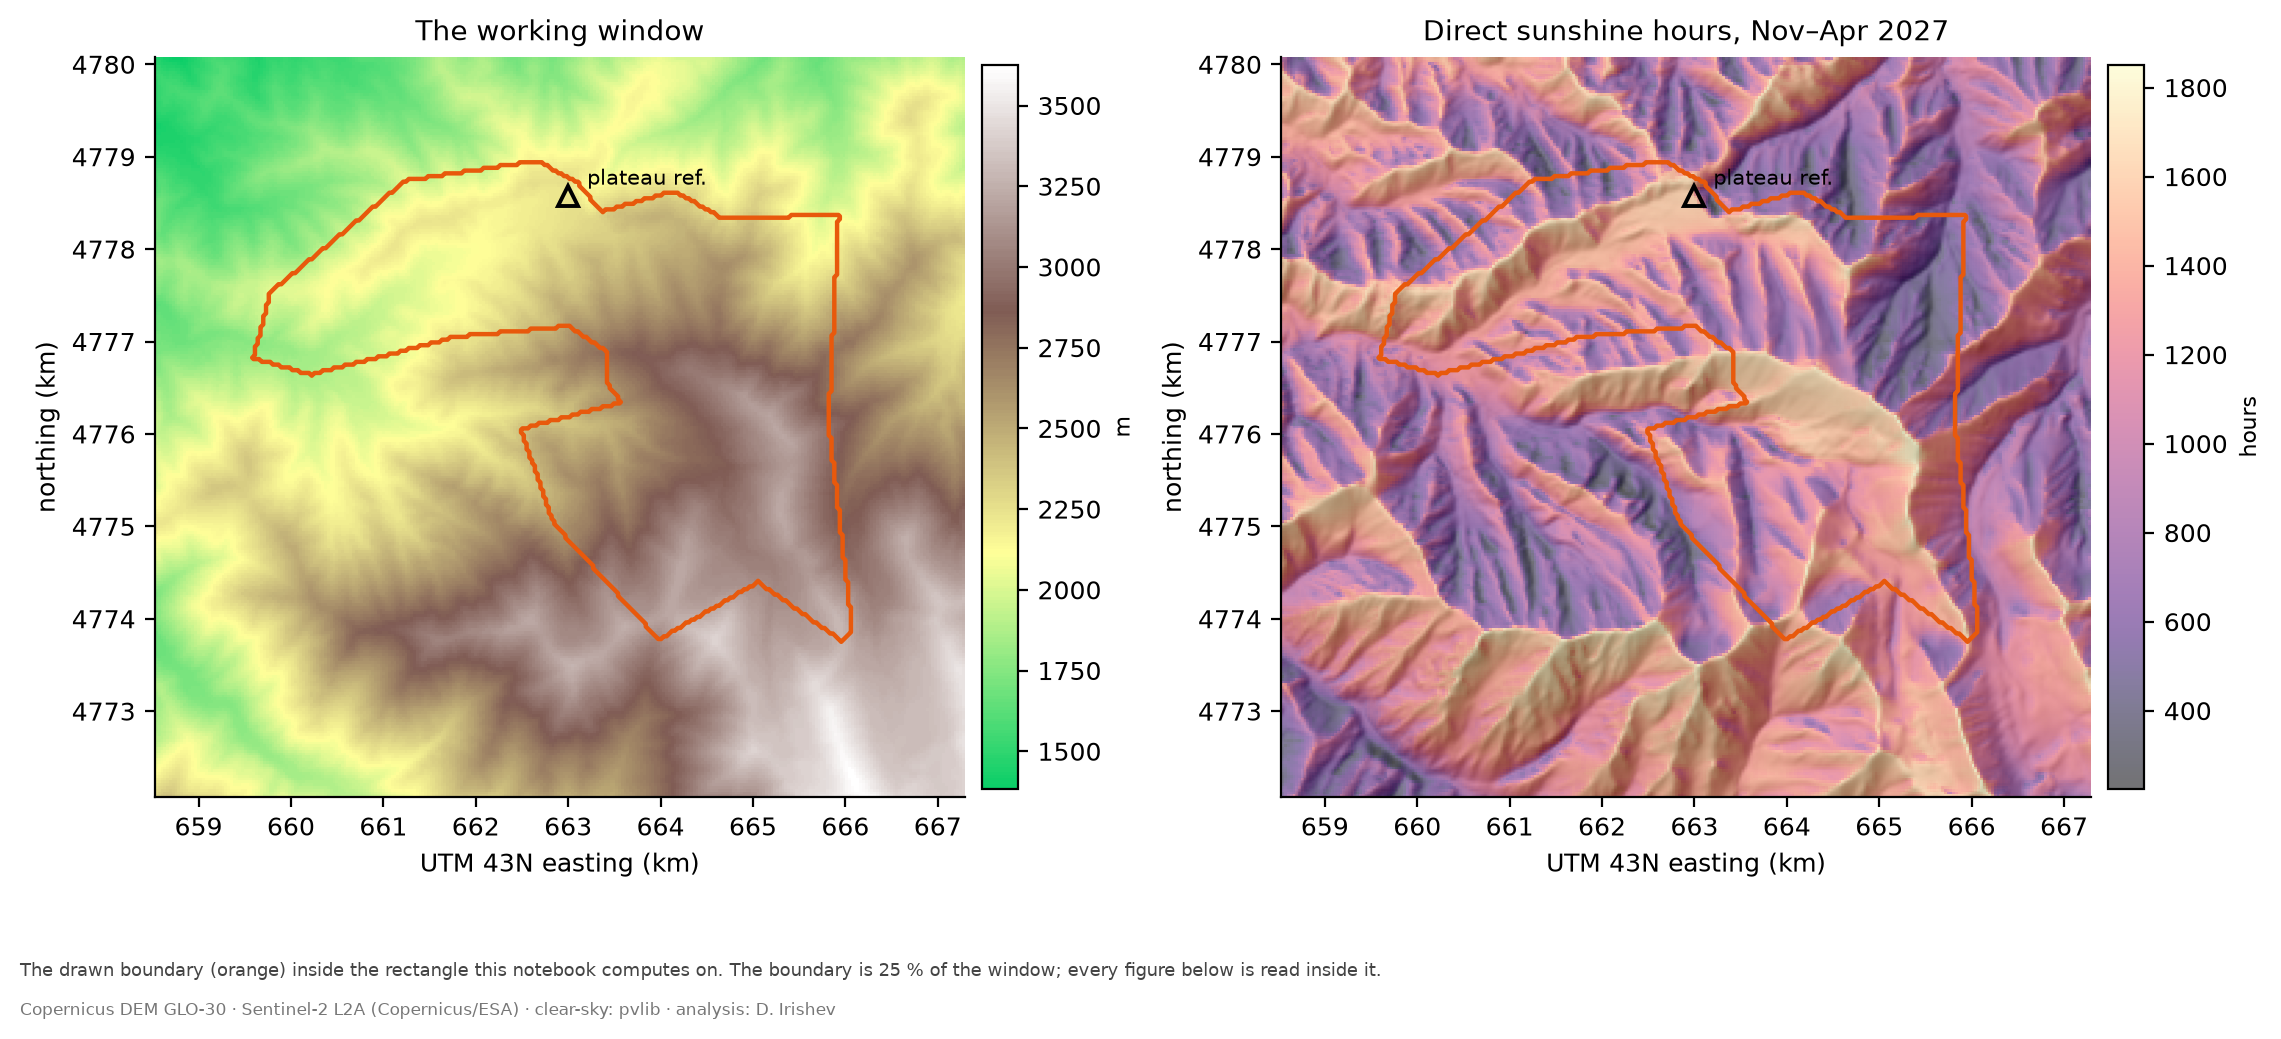

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/05_window_and_boundary.png')

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 5.0))
extent = (DEM_GRID.xmin / 1000, DEM_GRID.xmax / 1000,
          DEM_GRID.ymin / 1000, DEM_GRID.ymax / 1000)
map_panel(axes[0], t["dem"], DEM_GRID, cmap=ELEV_CMAP,
          title="The working window", cbar_label="m")
map_panel(axes[1], season_hours, DEM_GRID, cmap="magma", dem=t["dem"], shade=0.45,
          title=f"Direct sunshine hours, Nov\u2013Apr {OUTLOOK_YEAR}", cbar_label="hours")
for ax in axes:
    ax.contour(OA_MASK.astype(float), levels=[0.5], colors=["#e8590c"], linewidths=1.6,
               extent=extent, origin="upper", zorder=12)
fig.tight_layout()
save(fig, "05_window_and_boundary.png",
     f"The drawn boundary (orange) inside the rectangle this notebook computes on. "
     f"The boundary is {100 * OA_MASK.mean():.0f} % of the window; every figure below is "
     f"read inside it.")

## 2. Snow inside the boundary, from the scenes already read

The 20 m project grid is a pixel-aligned subset of the 20 m cluster grid, so
the 115 Sentinel-2 windows read for notebook 04 contain every observation this
window needs. `reuse_cache.py` asserts the alignment and slices the arrays; no
pixel is resampled and nothing is downloaded again. The cell below proves that
by re-reading one scene from the COGs and comparing bit for bit.

In [5]:
import reuse_cache as RC
import s2
from grids import grid_from_raster

cluster_s2 = grid_from_raster(Path.cwd().parent / "outputs" / "cluster" /
                              "geotiff" / "cluster_snow_frequency_month_03.tif")
RC.copy_stac_records(Path.cwd().parent / "data" / "interim" / "cluster")
slice_info = RC.slice_scene_cache(cluster_s2, S2_GRID)

recs = json.load(open(INTERIM / "stac_records.json"))
flat = [r for v in recs.values() for r in v]
probe = sorted(flat, key=lambda r: r["scene_id"])[len(flat) // 2]
cached = s2.fetch_scene(probe, S2_GRID)
fresh = s2.fetch_scene(probe, S2_GRID, force=True)
check = {k: int((cached[k].astype(bool) != fresh[k].astype(bool)).sum())
         for k in ("snow", "valid")}
print(f"\nre-read check on {probe['scene_id']}: "
      f"{check['snow']} snow and {check['valid']} validity pixels differ "
      f"out of {cached['snow'].size:,} — identical: {check == {'snow': 0, 'valid': 0}}")
pd.DataFrame([{**slice_info, "probe_scene": probe["scene_id"],
               "snow_pixels_differing": check["snow"],
               "valid_pixels_differing": check["valid"],
               "pixels_compared": int(cached["snow"].size)}]).to_csv(
    OUT_TAB / "scene_cache_reuse_check.csv", index=False)

STAC records: 115 scenes (reused from cluster)
scene cache 658320_4770420_1040x970_20m -> 658540_4772080_437x400_20m: 0 written, 115 already present (offset row 487, col 11; window 400x437)



re-read check on S2B_43TFH_20231126_0_L2A: 0 snow and 0 validity pixels differ out of 174,800 — identical: True


In [6]:
import resample
from pipeline_snow import coverage_table, current_season_days, historical_days, load_days
from snow import coverage_bias, select_days, snow_frequency
from config import SPRING_WINDOW

days, manifest, failed = load_days(verbose=False)
hist = historical_days(days)
print(f"dates: {len(days)} total, {len(hist)} inside the four completed seasons, "
      f"{len(failed)} failures")
manifest.to_csv(OUT_TAB / "scene_manifest.csv", index=False)

spring = select_days(hist, month_day_window=SPRING_WINDOW)
freq_spring = snow_frequency(spring)
freq_all = snow_frequency(hist)
print(coverage_table({"four seasons, all dates": hist,
                      "spring window, four seasons": spring}).to_string(index=False))

write_geotiff(OUT_TIF / "snow_frequency_4season.tif", freq_all["frequency"],
              S2_GRID, nodata=-9999,
              description="snow detection frequency, 4 seasons, equal season weight")
write_geotiff(OUT_TIF / "snow_frequency_spring_window_4season.tif",
              freq_spring["frequency"], S2_GRID, nodata=-9999,
              description=f"snow detection frequency, {SPRING_WINDOW[0]}..{SPRING_WINDOW[1]}, 4 seasons")

dates: 112 total, 111 inside the four completed seasons, 0 failures
                     period  n_dates  n_seasons  median_valid_obs_per_pixel  coverage_min4 first_date  last_date
    four seasons, all dates      111          4                          61         0.9927 2022-11-01 2026-04-29
spring window, four seasons       31          4                          28         0.9743 2023-03-11 2026-04-14


PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/geotiff/snow_frequency_spring_window_4season.tif')

### The bias this release used to leave implicit

A pixel only enters a monthly snow map once it has four cloud- and shadow-free
observations. Steep shaded ground fails that test more often, so the pixels
that qualify can be sunnier and gentler than the terrain as a whole — and in
December, when valid observations are scarcest, that skew falls straight on the
quantity being measured. `snow.coverage_bias` now measures it.

In [7]:
ins20 = resample.to_grid(season_kwh, src=DEM_GRID, dst=S2_GRID)
slope20 = resample.to_grid(t["slope"], src=DEM_GRID, dst=S2_GRID)
bias = coverage_bias(hist, {"insolation": ins20, "slope": slope20})
bias.to_csv(OUT_TAB / "snow_coverage_bias.csv", index=False)
print(bias[["month", "n_dates", "qualifying_share", "median_valid_obs",
            "insolation__qualifying", "insolation__whole_area", "insolation__skew",
            "slope__qualifying", "slope__whole_area", "slope__skew"]].to_string(index=False))
worst = bias.loc[bias.qualifying_share.idxmin()]
print(f"""
Thinnest month: {int(worst.month):02d}, {100*worst.qualifying_share:.0f} % of the window qualifies, and the
pixels that do sit {worst['insolation__skew']:+.0f} kWh/m² and {worst['slope__skew']:+.1f}° away from the area as a
whole. Any monthly snow figure for that month is a statement about the sunnier,
gentler part of the terrain, not about the terrain. Reported, not hidden.""")

 month  n_dates  qualifying_share  median_valid_obs  insolation__qualifying  insolation__whole_area  insolation__skew  slope__qualifying  slope__whole_area  slope__skew
    11       24            0.7192                13                  746.77                  590.45            156.32              28.97              30.86        -1.89
    12       16            0.4971                 3                  882.13                  590.45            291.68              29.50              30.86        -1.36
     1       16            0.5822                 8                  830.95                  590.45            240.50              29.14              30.86        -1.72
     2       13            0.8386                 9                  668.64                  590.45             78.20              30.16              30.86        -0.70
     3       25            0.9769                23                  601.91                  590.45             11.47              30.64              30.86

## 3. Kok Zhailau against Shymbulak and Oi-Qaragai — one rule for all three

The previous release compared Kok Zhailau against the OSM
`landuse=winter_sports` polygons for Shymbulak and Oi-Qaragai. Those are 2.2
and 1.0 km², far smaller than either resort operates, so the comparison was a
10 km² territory against a pair of map labels. `resorts.py` replaces it with
one rule for every place: **the ground within 150 m of its lift lines, unioned
with the ground within 100 m of its pistes.** Lines are assigned to the nearest
named place within 3.5 km; anything further stays unassigned.

Kok Zhailau has neither lifts nor pistes, because nothing is built there, so
it enters as the **drawn operating boundary** — the same polygon the rest of
this release measures, rasterised onto the cluster grid. That asymmetry is
real and cannot be removed: a working resort's corridors are *where planners
chose to build*, which is a selected sample of good terrain, while the drawn
boundary is a line round a whole mountainside. So the comparison below runs at
matched elevations and matched gradients, and the boundary is cut to skiable
gradients before any of it is read — otherwise the difference being measured
would be the difference between a corridor and a hillside.

In [8]:
import osm
import resorts
from grids import grid_from_raster

# This notebook is pinned to the project window, so config's AOI is the project
# window too. The OSM features for the comparison must therefore be clipped to
# the CLUSTER bbox explicitly, or Shymbulak and Oi-Qaragai fall outside and the
# comparison silently reduces to Kok Zhailau against nothing.
CLUSTER_BBOX = STUDY_AREAS["cluster"]["bbox"]
feat = osm.clip(osm.load(), bbox=CLUSTER_BBOX)

CG = Path.cwd().parent / "outputs" / "cluster" / "geotiff"
cluster_grid = grid_from_raster(CG / "cluster_elevation_m.tif")


def read_cluster(name):
    import rasterio
    with rasterio.open(CG / name) as s:
        a = s.read(1).astype("float32")
        if s.nodata is not None:
            a[a == s.nodata] = np.nan
    return a


c_dem = read_cluster("cluster_elevation_m.tif")
c_slope = read_cluster("cluster_slope_deg.tif")
c_ins = read_cluster(f"insolation_nov_apr_{OUTLOOK_YEAR}_kwh_m2.tif")
c_hrs = read_cluster(f"sun_hours_nov_apr_{OUTLOOK_YEAR}.tif")
c_snow20 = read_cluster("cluster_snow_frequency_month_03.tif")
c_snow = resample.to_grid(c_snow20, src=grid_from_raster(
    CG / "cluster_snow_frequency_month_03.tif"), dst=cluster_grid)

inv = resorts.inventory(feat)
inv.to_csv(OUT_TAB / "resort_inventory.csv", index=False)
print(inv[["place", "lifts", "lift_km", "pistes", "piste_km"]].to_string(index=False))
print("\nnamed lifts per place:")
for _, r in inv.iterrows():
    if r.named_lifts:
        print(f"  {r.place}: {r.named_lifts}")

c_oa = OA.mask(cluster_grid, poly)
areas = {"Kok Zhailau — drawn boundary": c_oa,
         **resorts.envelopes(cluster_grid, feat)}
print(f"\ndrawn boundary on the cluster grid: {c_oa.sum() * cluster_grid.res ** 2 / 1e4:,.0f} ha")
ha_c = cluster_grid.res ** 2 / 1e4
rows = []
for k, m in areas.items():
    rows.append({"area": k, "area_ha": round(m.sum() * ha_c, 1),
                 "elev_min_m": round(float(np.nanmin(c_dem[m])), 0),
                 "elev_median_m": round(float(np.nanmedian(c_dem[m])), 0),
                 "elev_max_m": round(float(np.nanmax(c_dem[m])), 0),
                 "slope_median_deg": round(float(np.nanmedian(c_slope[m])), 1),
                 "insolation_median": round(float(np.nanmedian(c_ins[m])), 0),
                 "sun_hours_median": round(float(np.nanmedian(c_hrs[m])), 0),
                 "snow_freq_march_median": round(float(np.nanmedian(c_snow[m])), 3)})
area_tbl = pd.DataFrame(rows)
area_tbl.to_csv(OUT_TAB / "three_area_overview.csv", index=False)
print()
print(area_tbl.to_string(index=False))

     place  lifts  lift_km  pistes  piste_km
 Shymbulak      7    10.73      24      18.6
Oi-Qaragai      8     6.51       6       4.7
unassigned      6     3.81       2       1.1

named lifts per place:
  Shymbulak: Combi-1; Combi-2; KKD-4; Left Talgar; T-Bar-1; T-Bar-2; Медеу - Шымбұлақ аспалы жолы
  Oi-Qaragai: Aqtas Expres; Barys; Jer-sy; Samal; Sanjar; Umai
  unassigned: 4-ый бугельный подъёмник, Elik Sai ski lift ~ 550м; Kok Tebe Cable Car; Pioneer ski area ski lift; Бугельный подъёмник учебной трассы, Elik Sai ski lift; Второй бугельный подъёмник, Elik Sai ski lift ~ 650 м

drawn boundary on the cluster grid: 1,776 ha

                        area  area_ha  elev_min_m  elev_median_m  elev_max_m  slope_median_deg  insolation_median  sun_hours_median  snow_freq_march_median
Kok Zhailau — drawn boundary   1775.5      1775.0         2568.0      3291.0              28.8              576.0            1188.0                   0.977
    Shymbulak operating area    377.6      1605.0     

Those medians are not yet a comparison: the areas sit at different altitudes
and different gradients, and both drive sun and snow. So the next table holds
both constant — every area restricted to skiable gradients, then compared band
by 200 m band, and only in bands where an area has at least 50 pixels.

In [9]:
ski_c = np.isfinite(c_slope) & (c_slope >= SKIABLE_SLOPE_MIN) & (c_slope <= SKIABLE_SLOPE_MAX)
areas_ski = {k: v & ski_c for k, v in areas.items()}
layers = {"insolation_kwh_m2": c_ins, "sun_hours": c_hrs, "snow_freq_march": c_snow}
bands = resorts.band_table(areas_ski, c_dem, layers, cluster_grid, step_m=200.0)
bands.to_csv(OUT_TAB / "three_area_elevation_bands.csv", index=False)
print(bands.pivot_table(index="band_m", columns="area",
                        values="insolation_kwh_m2").round(0).to_string())

REF = "Kok Zhailau — drawn boundary"
matched = pd.concat([resorts.matched_pairs(bands, lay, REF)
                     for lay in layers], ignore_index=True)
matched.to_csv(OUT_TAB / "three_area_matched_differences.csv", index=False)
print()
print(matched[["area", "layer", "shared_bands", "band_low_min_m", "band_low_max_m",
               "median_difference"]].to_string(index=False))

def mdiff(prefix, layer):
    sel = matched[matched.area.str.startswith(prefix) & (matched.layer == layer)]
    if sel.empty:
        raise AssertionError(f"no matched bands for {prefix} / {layer}: "
                             f"areas present = {sorted(matched.area.unique())}")
    return float(sel.median_difference.iloc[0])


shy_i, shy_s = mdiff("Shymbulak", "insolation_kwh_m2"), mdiff("Shymbulak", "snow_freq_march")
oq_i, oq_s = mdiff("Oi-Qaragai", "insolation_kwh_m2"), mdiff("Oi-Qaragai", "snow_freq_march")
print(f"""
Against the drawn boundary, at matched elevations and matched gradients:

  Shymbulak's working corridors receive {shy_i:+.0f} kWh/m² of winter energy and hold
  snow {shy_s:+.3f} more often in March. They trade sun for snow.
  Oi-Qaragai receives {oq_i:+.0f} kWh/m² and holds snow {oq_s:+.3f} more often — but it sits
  at 1,520-2,280 m under forest, where NDSI under canopy is a known weak point,
  so its snow figure is the least comparable number in this table.

Sun and snow do not rank these places the same way. That is the same result
notebook 04 found *within* one area, reappearing *between* areas.""")

area       Kok Zhailau — drawn boundary  Oi-Qaragai operating area  Shymbulak operating area
band_m                                                                                      
1400-1600                           NaN                      718.0                       NaN
1600-1800                           NaN                      541.0                     384.0
1800-2000                         881.0                      619.0                     556.0
2000-2200                         627.0                      721.0                     658.0
2200-2400                         475.0                      661.0                     582.0
2400-2600                         453.0                        NaN                     456.0
2600-2800                         479.0                        NaN                     391.0
2800-3000                         599.0                        NaN                     459.0
3000-3200                         730.0                        NaN    

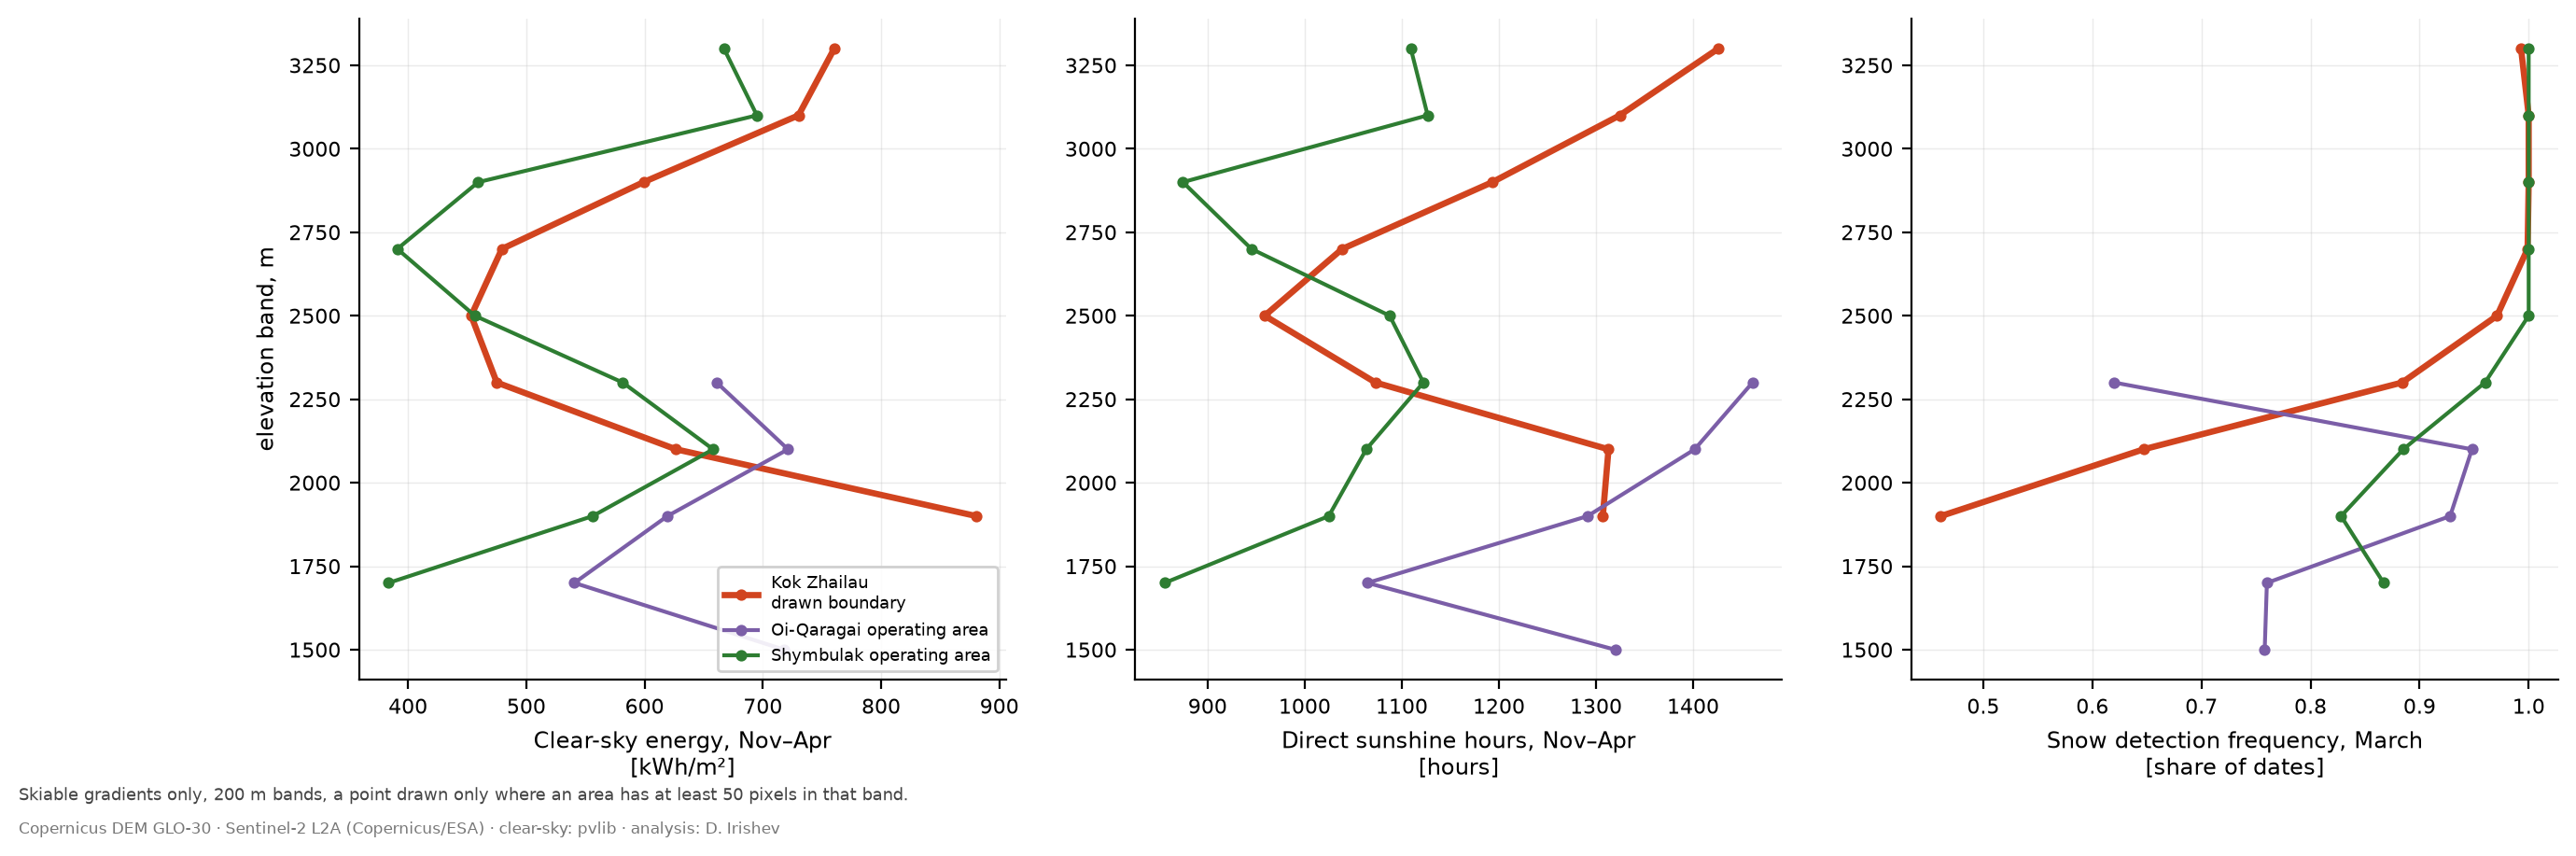

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/05_three_area_elevation_bands.png')

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.6))
for ax, (lay, lab, unit) in zip(axes, [
        ("insolation_kwh_m2", "Clear-sky energy, Nov–Apr", "kWh/m²"),
        ("sun_hours", "Direct sunshine hours, Nov–Apr", "hours"),
        ("snow_freq_march", "Snow detection frequency, March", "share of dates")]):
    for name, d in bands.groupby("area"):
        d = d.sort_values("band_low_m")
        style = dict(marker="o", ms=3.4, lw=1.5)
        if name.startswith("Kok Zhailau"):
            style.update(color="#d1441f", lw=2.4)
        elif name.startswith("Shymbulak"):
            style.update(color="#2e7d32")
        else:
            style.update(color="#7b5ea7")
        ax.plot(d[lay], d.band_low_m + 100, label=name.replace(" — ", "\n"), **style)
    ax.set_xlabel(f"{lab}\n[{unit}]", fontsize=8.5)
    ax.grid(alpha=0.25, lw=0.5)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("elevation band, m", fontsize=8.5)
axes[0].legend(fontsize=6.4, loc="lower right", framealpha=0.9)
save(fig, "05_three_area_elevation_bands.png",
     "Skiable gradients only, 200 m bands, a point drawn only where an area has "
     "at least 50 pixels in that band.")

## 4. Engineering check: does the DEM choice change the answer?

Three global DEMs agree on elevation to a few metres, and a table of elevation
differences is the half of a DEM check that flatters every product. The
planning does not read elevation — it reads slope, horizon, insolation and
sunshine hours. So the **whole chain** is re-run on NASADEM (SRTM, 2000) and
ALOS World 3D-30m, and the products are compared, on skiable gradients only.

In [11]:
import dem_validation as DV
from insolation import accumulate_insolation
from sunhours import sunshine_hours

alt_terrain = {k: DV.terrain_from(k, DEM_GRID) for k in DV.COLLECTIONS}
lonc, latc = DEM_GRID.lonlat_centers()
clat, clon = float(np.mean(latc)), float(np.mean(lonc))
PCACHE = INTERIM / "dem_validation"
PCACHE.mkdir(parents=True, exist_ok=True)


def dem_products(name, tt):
    p = PCACHE / f"products_{name.replace(' ', '_')}.npz"
    if p.exists():
        z = np.load(p)
        return {k: z[k] for k in z.files}
    i1 = accumulate_insolation(f"{OUTLOOK_YEAR}-11-01", f"{OUTLOOK_YEAR+1}-04-30",
                               tt["dem"], tt["slope"], tt["aspect"], tt["svf"],
                               tt["azimuths"], tt["horizon"], clat, clon, verbose=False)
    i2 = accumulate_insolation(f"{OUTLOOK_YEAR}-12-01", f"{OUTLOOK_YEAR}-12-31",
                               tt["dem"], tt["slope"], tt["aspect"], tt["svf"],
                               tt["azimuths"], tt["horizon"], clat, clon, verbose=False)
    h = sunshine_hours(f"{OUTLOOK_YEAR}-11-01", f"{OUTLOOK_YEAR+1}-04-30", tt,
                       clat, clon, by_month=False)
    out = {"ins_nov_apr": i1["total"], "ins_dec": i2["total"], "hours": h["hours"]}
    np.savez_compressed(p, **out)
    return out


prod = {"Copernicus GLO-30": dem_products("Copernicus GLO-30", t)}
for k, v in alt_terrain.items():
    prod[k] = dem_products(k, v)
others_t = {k: v for k, v in alt_terrain.items()}
ref_prod = prod["Copernicus GLO-30"]
others_p = {k: v for k, v in prod.items() if k != "Copernicus GLO-30"}
ski = np.isfinite(t["slope"]) & (t["slope"] >= SKIABLE_SLOPE_MIN) & (t["slope"] <= SKIABLE_SLOPE_MAX)
print(f"comparison mask: {int(ski.sum()):,} skiable pixels "
      f"({ski.sum()*PX_HA:,.0f} ha of the {DEM_GRID.area_km2*100:,.0f} ha window)")

inputs = pd.concat([
    DV.compare_layer(t["dem"], {k: v["dem"] for k, v in others_t.items()}, "elevation_m", ski),
    DV.compare_layer(t["slope"], {k: v["slope"] for k, v in others_t.items()}, "slope_deg", ski),
    DV.compare_layer(t["svf"], {k: v["svf"] for k, v in others_t.items()}, "sky_view_factor", ski),
], ignore_index=True)
products = pd.concat([
    DV.compare_layer(ref_prod["ins_nov_apr"], {k: v["ins_nov_apr"] for k, v in others_p.items()},
                     "insolation_nov_apr_kwh_m2", ski, relative=True),
    DV.compare_layer(ref_prod["ins_dec"], {k: v["ins_dec"] for k, v in others_p.items()},
                     "insolation_december_kwh_m2", ski, relative=True),
    DV.compare_layer(ref_prod["hours"], {k: v["hours"] for k, v in others_p.items()},
                     "direct_sun_hours_nov_apr", ski, relative=True),
], ignore_index=True)
dem_chain = pd.concat([inputs, products], ignore_index=True)
dem_chain.to_csv(OUT_TAB / "dem_propagation.csv", index=False)
print()
print(dem_chain[["layer", "dem", "diff_median", "diff_std", "diff_p95_abs",
                 "pct_p95_abs", "correlation"]].to_string(index=False))

comparison mask: 49,883 skiable pixels (4,489 ha of the 7,017 ha window)

                     layer         dem  diff_median  diff_std  diff_p95_abs  pct_p95_abs  correlation
               elevation_m     NASADEM        0.387     6.607        13.446          NaN     0.999916
               elevation_m ALOS AW3D30        2.089     5.054        11.114          NaN     0.999950
                 slope_deg     NASADEM       -1.218     3.506         7.528          NaN     0.826749
                 slope_deg ALOS AW3D30        0.250     2.718         5.930          NaN     0.892666
           sky_view_factor     NASADEM        0.010     0.020         0.047          NaN     0.904864
           sky_view_factor ALOS AW3D30       -0.002     0.016         0.034          NaN     0.946780
 insolation_nov_apr_kwh_m2     NASADEM        3.599    59.695       123.302       22.613     0.981308
 insolation_nov_apr_kwh_m2 ALOS AW3D30       -1.682    38.047        77.595       17.248     0.992515
insolati

In [12]:
ranks = []
for key, lab in [("ins_nov_apr", "insolation_nov_apr_kwh_m2"),
                 ("ins_dec", "insolation_december_kwh_m2"),
                 ("hours", "direct_sun_hours_nov_apr")]:
    for k, v in others_p.items():
        r = DV.rank_shift(ref_prod[key], v[key], ski)
        if r:
            ranks.append({"layer": lab, "dem": k, **r})
rank_tbl = pd.DataFrame(ranks)
rank_tbl.to_csv(OUT_TAB / "dem_rank_stability.csv", index=False)
print(rank_tbl[["layer", "dem", "top_n", "overlap", "overlap_share",
                "spearman_rho"]].to_string(index=False))

e_r = dem_chain[(dem_chain.layer == "elevation_m")].correlation.min()
s_r = dem_chain[(dem_chain.layer == "slope_deg")].correlation.min()
dec = dem_chain[dem_chain.layer == "insolation_december_kwh_m2"]
print(f"""
The result an employer should take from this section:

  elevation agrees at r = {e_r:.4f}; slope, built from the same pixels, at r = {s_r:.3f}.
  Agreement does not survive differentiation, and differentiation is where the
  planning lives.

  Bias is negligible — December median difference {dec.diff_median.abs().max():.1f} kWh/m² at worst — but
  the spread is not: at the 95th percentile the December figure moves by
  {dec.pct_p95_abs.min():.0f}-{dec.pct_p95_abs.max():.0f} % of its own value depending on which open DEM you used.

  What does survive is the ranking: {100*rank_tbl.overlap_share.min():.0f}-{100*rank_tbl.overlap_share.max():.0f} % of the top tenth of terrain is
  the same ground whichever DEM is chosen, at Spearman {rank_tbl.spearman_rho.min():.3f}-{rank_tbl.spearman_rho.max():.3f}.

So: screen sites with this, on any of the three. Do not sign off a single
site's December number on it without measurement.""")

                     layer         dem  top_n  overlap  overlap_share  spearman_rho
 insolation_nov_apr_kwh_m2     NASADEM   4988     4171         0.8362      0.977347
 insolation_nov_apr_kwh_m2 ALOS AW3D30   4988     4691         0.9405      0.987759
insolation_december_kwh_m2     NASADEM   4988     4257         0.8534      0.969141
insolation_december_kwh_m2 ALOS AW3D30   4988     4709         0.9441      0.980168
  direct_sun_hours_nov_apr     NASADEM   4988     4337         0.8695      0.971891
  direct_sun_hours_nov_apr ALOS AW3D30   4988     4666         0.9354      0.983858

The result an employer should take from this section:

  elevation agrees at r = 0.9999; slope, built from the same pixels, at r = 0.827.
  Agreement does not survive differentiation, and differentiation is where the
  planning lives.

  Bias is negligible — December median difference 0.2 kWh/m² at worst — but
  the spread is not: at the 95th percentile the December figure moves by
  37-59 % of its own value

## 5. Weather data: what reanalysis can carry, and where it stops

A December opening is a weather commitment, so the weather inputs deserve the
same treatment as the DEM. Two things matter here and neither is a detail:

* **Reanalysis resolution against this relief.** ERA5-Land is ~9 km and ERA5
  ~31 km. The project window is 6 km across and spans 1,867 m of relief. A
  single ERA5 cell flattens the whole mountain, so reanalysis here is a
  *regional season descriptor*, not a site record.
* **ERA5-Land returns no precipitation at this point** through the archive API,
  so snowfall comes from ERA5 instead and is labelled separately rather than
  silently summed to zero — which is what an all-NaN sum would have produced.

In [13]:
import weather
from config import SEASONS

wx = weather.era5_land_daily("2022-11-01", f"{date.today().year}-{date.today().month:02d}-01")
wx_season = weather.season_summary(wx, SEASONS)
wx_season.to_csv(OUT_TAB / "reanalysis_season_summary.csv", index=False)
print(wx_season.to_string(index=False))
print("\nsources:", json.dumps(wx.attrs, indent=1)[:600])

monthly = (wx.assign(month=wx["date"].dt.month)
           .groupby("month")
           .agg(mean_T_C=("temperature_2m_mean", "mean"),
                min_T_C=("temperature_2m_min", "min"),
                days_Tmax_below_0C=("temperature_2m_max", lambda s: int((s < 0).sum())),
                n_days=("temperature_2m_mean", "size"))
           .round(2).reset_index())
monthly = monthly[monthly.month.isin([11, 12, 1, 2, 3, 4])]
monthly.to_csv(OUT_TAB / "reanalysis_monthly_climatology.csv", index=False)
print()
print(monthly.to_string(index=False))

outlooks = json.load(open(Path.cwd().parent / "docs" / "seasonal_outlooks.json"))
print("\npublished seasonal outlooks on file:")
for k, v in outlooks.items():
    print(f"  {k}: {v.get('issuer','')[:60]} | issued {v.get('issued','?')} | "
          f"{v.get('spatial_scale','')[:58]}")

 season  n_days  mean_T_C  days_Tmax_below_0C  snowfall_sum_cm  precip_sum_mm
2022/23     181     -3.88                  94            122.2          391.1
2023/24     182     -3.20                  81            149.4          420.0
2024/25     181     -3.60                  96            107.3          298.8
2025/26     181     -1.89                  68            110.6          343.6

sources: {
 "temperature_dataset": "ERA5-Land daily via Open-Meteo Historical Weather API (~9 km grid)",
 "precipitation_dataset": "ERA5 (~31 km) - ERA5-Land returned no precipitation at this point",
 "precip_model_used": "era5",
 "request_point_lon": 77.00433,
 "request_point_lat": 43.14239,
 "model_grid_elevation_m": 2235.0,
 "timezone": "Asia/Almaty",
 "units": {
  "time": "iso8601",
  "temperature_2m_mean": "\u00b0C",
  "temperature_2m_min": "\u00b0C",
  "temperature_2m_max": "\u00b0C",
  "snowfall_sum": "cm",
  "precipitation_sum": "mm"
 },
 "retrieved": "2026-11-24",
 "caveat": "Both reanalyses a

## 6. What this cannot settle, and what I would measure

Everything above is geometry and detection frequency. Neither is a snowpack,
and no amount of further processing turns one into the other. The table below
is the handover: the quantities a GIS or engineering team would still have to
obtain locally, and why orbit cannot supply them.

In [14]:
needed = pd.DataFrame([
    {"question": "snow depth and water equivalent",
     "needed_measurement": "snow pillow or ultrasonic depth sensor plus manual density "
                           "cores, on at least one shaded and one sunny plot in the "
                           "same elevation band",
     "why_satellite_cannot": "optical imagery sees the surface, not the depth below it"},
    {"question": "real (not clear-sky) irradiance",
     "needed_measurement": "two pyranometers on contrasting aspects inside the boundary",
     "why_satellite_cannot": "the model here is clear-sky by construction; cloud "
                             "attenuation is unmeasured"},
    {"question": "the December sun figure for one specific site",
     "needed_measurement": "a horizon survey from the site, or a short-baseline "
                           "photogrammetric or lidar DEM",
     "why_satellite_cannot": f"the three open DEMs disagree by "
                             f"{dec.pct_p95_abs.min():.0f}-{dec.pct_p95_abs.max():.0f} % at the 95th percentile on "
                             f"exactly this quantity (section 4)"},
    {"question": "snowmaking windows",
     "needed_measurement": "wet-bulb temperature at the gun line, wind speed and "
                           "direction, water yield and temperature, equipment curves",
     "why_satellite_cannot": "none of these quantities is observed from orbit"},
    {"question": "season opening date",
     "needed_measurement": "a continuous depth record against an operating threshold, "
                           "over several seasons",
     "why_satellite_cannot": "a 5-day revisit with cloud gaps cannot resolve a "
                             "threshold crossing to the day"},
    {"question": "avalanche terrain classification",
     "needed_measurement": "snowpack profiles, wind transport and loading patterns, "
                           "mapped start and runout zones, local forecaster judgement",
     "why_satellite_cannot": "slope angle is geometry; release depends on the snowpack"},
    {"question": "mid-winter snow statistics on shaded ground",
     "needed_measurement": "ground observation, or Sentinel-1 SAR wet-snow retrieval "
                           "to see through cloud",
     "why_satellite_cannot": f"in the thinnest month only "
                             f"{100*worst.qualifying_share:.0f} % of the boundary has four clear "
                             f"observations, and that subset is biased "
                             f"{worst['insolation__skew']:+.0f} kWh/m² sunnier (section 2)"},
    {"question": "where the beginner terrain can physically go",
     "needed_measurement": "a design-grade survey of the gentle benches and of what can "
                           "be linked by lift",
     "why_satellite_cannot": f"a 30 m DEM resolves that the gentle ground inside the "
                             f"boundary arrives in {int(oa_terrain.green_blue_pieces.iloc[0])} "
                             f"pieces, not whether two of them can be joined"},
])
needed.to_csv(OUT_TAB / "local_measurements_required.csv", index=False)
for _, r in needed.iterrows():
    print(f"\n{r['question']}\n  need : {r['needed_measurement']}\n  why  : {r['why_satellite_cannot']}")


snow depth and water equivalent
  need : snow pillow or ultrasonic depth sensor plus manual density cores, on at least one shaded and one sunny plot in the same elevation band
  why  : optical imagery sees the surface, not the depth below it

real (not clear-sky) irradiance
  need : two pyranometers on contrasting aspects inside the boundary
  why  : the model here is clear-sky by construction; cloud attenuation is unmeasured

the December sun figure for one specific site
  need : a horizon survey from the site, or a short-baseline photogrammetric or lidar DEM
  why  : the three open DEMs disagree by 37-59 % at the 95th percentile on exactly this quantity (section 4)

snowmaking windows
  need : wet-bulb temperature at the gun line, wind speed and direction, water yield and temperature, equipment curves
  why  : none of these quantities is observed from orbit

season opening date
  need : a continuous depth record against an operating threshold, over several seasons
  why  : a 5-day r

In [15]:
meta = {
    "run_date": RUN_DATE,
    "area": AREA_LABEL,
    "bbox": list(AOI_BBOX_WGS84),
    "window_km2": round(DEM_GRID.area_km2, 2),
    "derivation": AREA_NOTE,
    "operating_boundary": {
        "stated_territory_ha": PROJECT_AREA_HA,
        "drawn_area_ha": round(float(OA_MASK.sum() * PX_HA), 1),
        "share_of_window": round(float(OA_MASK.mean()), 3),
        "green_blue_ha": float(oa_terrain.green_blue_ha.iloc[0]),
        "green_blue_pieces": int(oa_terrain.green_blue_pieces.iloc[0]),
        "green_blue_largest_ha": float(oa_terrain.green_blue_largest_ha.iloc[0]),
        "provenance": OA.provenance(poly_props),
    },
    "sun": {"horizon_azimuths": HORIZON_N_AZIMUTH,
            "sunshine_step_min": SUN_HOUR_STEP_MIN,
            "nov_apr_hours_median_inside": round(float(np.nanmedian(season_hours[OA_MASK])), 1)},
    "snow": {"scenes": int(len(manifest)), "dates": int(len(days)),
             "failures": int(len(failed)),
             "scene_cache_reused_from": slice_info["source"],
             "reuse_check_differing_pixels": int(check["snow"] + check["valid"]),
             "thinnest_month": int(worst.month),
             "thinnest_month_qualifying_share": float(worst.qualifying_share)},
    "dem_validation": {
        "collections": DV.COLLECTIONS,
        "elevation_min_correlation": float(e_r),
        "slope_min_correlation": float(s_r),
        "top_decile_overlap_min": float(rank_tbl.overlap_share.min()),
        "top_decile_overlap_max": float(rank_tbl.overlap_share.max()),
    },
    "three_area_reference": REF,
}
(OUT_TIF / "project_metadata.json").write_text(json.dumps(meta, indent=1))
print(json.dumps(meta, indent=1)[:1500])
print("\ntables:", sorted(p.name for p in OUT_TAB.glob("*.csv")))
print("figures:", sorted(p.name for p in OUT_PNG.glob("*.png")))

{
 "run_date": "2026-11-24",
 "area": "Almaty SuperSki - the drawn operating boundary and its working window",
 "bbox": [
  76.95,
  43.085,
  77.055,
  43.155
 ],
 "window_km2": 70.17,
 "derivation": "The study area is the boundary in qgis/operating_area.geojson, hand-digitised over satellite imagery. This rectangle is nothing more than that boundary's own envelope plus the 1 km working buffer operating_area.bbox() returns: rasters need a margin for hillshade and for the horizon to have surroundings, and a map needs context around its subject. Every figure reported for the operating area is masked to the boundary. Earlier releases ran on two larger author-chosen rectangles - a 69 km2 box around the plateau and a 125 km2 envelope of the general-plan control points - and both reached about 3 km north of the boundary into the dacha belt below 1,775 m, which is ground this study has no business measuring. Both are withdrawn.",
 "operating_boundary": {
  "stated_territory_ha": 1022.0,
  "d